In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Main Model**

In [ ]:
import os
import numpy as np
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Dense, Dropout,
                                     BatchNormalization, GlobalAveragePooling2D,
                                     Input)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
import warnings
import joblib

In [ ]:
# ปิดการแสดงคำเตือนที่ไม่จำเป็น
warnings.filterwarnings('ignore')

# --- ค่าคงที่และพารามิเตอร์หลัก ---
# กำหนดพาธไปยังโฟลเดอร์ที่เก็บชุดข้อมูลเสียงร้องของทารก
DATA_PATH = os.path.join(os.getcwd(), '/content/drive/MyDrive/new_cry_baby_dataset_80_10_10/cry_baby_dataset')

# กำหนดค่าพารามิเตอร์สำหรับการประมวลผลเสียง
SAMPLE_RATE = 16000  # อัตราการสุ่มตัวอย่าง (Hz)
DURATION = 7         # ความยาวของเสียงที่ต้องการ (วินาที)
N_MELS = 128         # จำนวน Mel bands ที่จะใช้ในการสร้าง Mel spectrogram
HOP_LENGTH = 512     # ขนาดของ hop length สำหรับการทำ STFT

# กำหนดป้ายกำกับ (Label) ของประเภทเสียงร้อง
LABELS = ['belly pain', 'burping', 'discomfort', 'hungry', 'tired']

In [ ]:
class DataProcessor:
    """
    คลาสสำหรับจัดการการโหลด, ประมวลผล, และสกัดคุณลักษณะจากข้อมูลเสียงร้องของทารก
    """
    def __init__(self, data_path, sample_rate=16000, duration=7):
        """
        Constructor ของคลาส
        :param data_path: พาธไปยังชุดข้อมูล
        :param sample_rate: อัตราการสุ่มตัวอย่าง
        :param duration: ความยาวของเสียงที่ต้องการ (วินาที)
        """
        self.data_path = data_path
        self.sample_rate = sample_rate
        self.duration = duration
        self.max_len = sample_rate * duration  # คำนวณความยาวสูงสุดของสัญญาณเสียง (จำนวน sample)

    def load_and_preprocess_audio(self, file_path):
        """
        โหลดไฟล์เสียงและปรับความยาวให้เท่ากัน
        :param file_path: พาธของไฟล์เสียง
        :return: สัญญาณเสียง (audio signal) ที่ปรับความยาวแล้ว
        """
        try:
            # โหลดไฟล์เสียงด้วย librosa, กำหนด sample rate และความยาว
            audio, sr = librosa.load(file_path, sr=self.sample_rate, duration=self.duration)
            # ตรวจสอบว่าเสียงสั้นกว่าความยาวที่กำหนดหรือไม่
            if len(audio) < self.max_len:
                # ถ้าสั้นกว่า ให้เติมความเงียบ (padding) เข้าไปจนครบ
                audio = np.pad(audio, (0, self.max_len - len(audio)), mode='constant')
            else:
                # ถ้าเสียงยาวกว่า ให้ตัดส่วนเกินออก
                audio = audio[:self.max_len]
            return audio
        except Exception as e:
            # จัดการข้อผิดพลาดหากไม่สามารถโหลดไฟล์ได้
            print(f"Error loading {file_path}: {e}")
            return None

    def apply_data_augmentation(self, audio):
        """
        เพิ่มจำนวนข้อมูล (Data Augmentation) เพื่อให้โมเดลเรียนรู้ได้ดีขึ้น
        :param audio: สัญญาณเสียงต้นฉบับ
        :return: ลิสต์ของสัญญาณเสียงที่ผ่านการ augmentation แล้ว (รวมต้นฉบับ)
        """
        augmented_samples = [audio]  # เริ่มด้วยเสียงต้นฉบับ
        # 1. Pitch Shifting: เปลี่ยนระดับเสียง (pitch) ขึ้น 2 semitones
        pitch_shifted = librosa.effects.pitch_shift(audio, sr=self.sample_rate, n_steps=2)
        augmented_samples.append(pitch_shifted)
        # 2. Time Stretching: ยืด/หดเวลาของเสียง (ในที่นี้คือทำให้ช้าลง rate=0.9)
        time_stretched = librosa.effects.time_stretch(audio, rate=0.9)
        # ปรับความยาวของเสียงที่ถูกยืด/หดให้เท่ากับความยาวมาตรฐาน
        if len(time_stretched) < self.max_len:
            time_stretched = np.pad(time_stretched, (0, self.max_len - len(time_stretched)), mode='constant')
        else:
            time_stretched = time_stretched[:self.max_len]
        augmented_samples.append(time_stretched)
        # 3. Adding Noise: เพิ่มสัญญาณรบกวน (noise) แบบสุ่มเข้าไปในเสียง
        noise = np.random.normal(0, 0.005, len(audio))
        noisy_audio = audio + noise
        augmented_samples.append(noisy_audio)
        return augmented_samples

    def extract_features(self, audio):
        """
        สกัดคุณลักษณะ (feature) จากสัญญาณเสียงในรูปแบบ Mel Spectrogram
        :param audio: สัญญาณเสียง
        :return: ดิกชันนารีที่มี 'mel_spectrogram' ที่ผ่านการ normalize แล้ว
        """
        features = {}
        # 1. สร้าง Mel Spectrogram
        mel_spec = librosa.feature.melspectrogram(
            y=audio, sr=self.sample_rate, n_mels=N_MELS, hop_length=HOP_LENGTH
        )
        # 2. แปลงค่าพลังงาน (power) เป็นเดซิเบล (dB) ซึ่งใกล้เคียงกับการรับรู้ของมนุษย์
        log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
        # 3. ทำ Normalization (Standardization) เพื่อให้ค่ามีการกระจายตัวอยู่รอบ 0
        log_mel_spec_norm = (log_mel_spec - log_mel_spec.mean()) / (log_mel_spec.std() + 1e-8)
        features['mel_spectrogram'] = log_mel_spec_norm
        return features

In [ ]:
def build_deep_cnn_model(input_shape, num_classes):
    """
    สร้างสถาปัตยกรรมโมเดล Deep Convolutional Neural Network (CNN)
    :param input_shape: ขนาดของข้อมูลนำเข้า (height, width, channels)
    :param num_classes: จำนวนคลาสที่ต้องการจำแนก
    :return: โมเดล Keras ที่ยังไม่ได้ compile
    """
    model = Sequential([
        Input(shape=input_shape),
        # Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same'), # สกัด feature พื้นฐาน
        BatchNormalization(), # ช่วยให้โมเดลฝึกได้เร็วและเสถียรขึ้น
        MaxPooling2D((2, 2)), # ลดขนาดของ feature map ลง
        # Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same'), # สกัด feature ที่ซับซ้อนขึ้น
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        # Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same'), # สกัด feature ที่ซับซ้อนยิ่งขึ้น
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        # Flattening and Dense Layers
        GlobalAveragePooling2D(), # แปลง feature map 2D เป็น vector 1D
        Dense(128, activation='relu'), # ชั้น fully-connected สำหรับการเรียนรู้รูปแบบ
        Dropout(0.5), # ป้องกัน Overfitting
        Dense(64, activation='relu'),
        Dropout(0.3),
        # Output Layer
        Dense(num_classes, activation='softmax') # ชั้นสุดท้ายสำหรับจำแนกคลาส
    ])
    return model

In [ ]:
def load_dataset(data_path):
    """
    โหลดชุดข้อมูลทั้งหมด, ประมวลผล, และแปลงให้อยู่ในรูปแบบที่พร้อมสำหรับโมเดล
    :param data_path: พาธไปยังโฟลเดอร์หลักของชุดข้อมูล
    :return: X_mel (ข้อมูล), y_categorical (label แบบ one-hot), y_encoded (label แบบตัวเลข), label_encoder
    """
    processor = DataProcessor(data_path, sample_rate=SAMPLE_RATE, duration=DURATION)
    X_mel = [] # ลิสต์สำหรับเก็บ feature (Mel spectrograms)
    y = []     # ลิสต์สำหรับเก็บ label (ชื่อคลาส)
    print("Loading and processing audio files...")
    # วนลูปในแต่ละโฟลเดอร์ของ label
    for label in LABELS:
        label_path = os.path.join(data_path, label)
        if not os.path.exists(label_path):
            print(f"Warning: {label_path} not found! Skipping...")
            continue
        # อ่านรายชื่อไฟล์ .wav ทั้งหมดในโฟลเดอร์
        audio_files = [f for f in os.listdir(label_path) if f.endswith('.wav')]
        for file_name in audio_files:
            file_path = os.path.join(label_path, file_name)
            # โหลดและประมวลผลเสียง
            audio = processor.load_and_preprocess_audio(file_path)
            if audio is not None:
                # ทำ Data Augmentation
                augmented_samples = processor.apply_data_augmentation(audio)
                # วนลูปในแต่ละเสียงที่ได้จากการ augment
                for aug_audio in augmented_samples:
                    # สกัด feature
                    features = processor.extract_features(aug_audio)
                    X_mel.append(features['mel_spectrogram'])
                    y.append(label)

    # แปลงลิสต์เป็น NumPy array
    X_mel = np.array(X_mel)
    # เพิ่มมิติของ channel (สำหรับ CNN) -> (samples, height, width, 1)
    X_mel = X_mel.reshape(X_mel.shape[0], X_mel.shape[1], X_mel.shape[2], 1)

    # แปลง label ที่เป็นข้อความให้เป็นตัวเลข (0, 1, 2, ...)
    label_encoder = LabelEncoder()
    y_encoded = label_encoder.fit_transform(y)
    # แปลง label ตัวเลขให้เป็นรูปแบบ One-Hot Encoding (สำคัญสำหรับ categorical_crossentropy)
    y_categorical = to_categorical(y_encoded, num_classes=len(LABELS))

    return X_mel, y_categorical, y_encoded, label_encoder

In [ ]:
def split_data(X, y, y_encoded):
    """
    แบ่งข้อมูลเป็นชุด Training, Validation, และ Test
    :param X: ข้อมูล feature
    :param y: ข้อมูล label (one-hot)
    :param y_encoded: ข้อมูล label (ตัวเลข)
    :return: ข้อมูลที่แบ่งแล้ว 8 ชุด
    """
    # แบ่งข้อมูล 80% เป็น train และ 20% เป็น temp (val+test)
    # stratify=y_encoded เพื่อให้สัดส่วนของแต่ละคลาสใน train และ temp ใกล้เคียงกับข้อมูลทั้งหมด
    X_train, X_temp, y_train, y_temp, y_enc_train, y_enc_temp = train_test_split(
        X, y, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )
    # แบ่งข้อมูล temp 50% เป็น validation และ 50% เป็น test
    X_val, X_test, y_val, y_test, y_enc_val, y_enc_test = train_test_split(
        X_temp, y_temp, y_enc_temp, test_size=0.5, random_state=42, stratify=y_enc_temp
    )
    print(f"Training set: {X_train.shape[0]} samples")
    print(f"Validation set: {X_val.shape[0]} samples")
    print(f"Test set: {X_test.shape[0]} samples")
    return X_train, X_val, X_test, y_train, y_val, y_test, y_enc_train, y_enc_val, y_enc_test

In [ ]:
def plot_training_history(history, save_path):
    """
    พล็อตกราฟ Loss และ Accuracy จากประวัติการ train
    :param history: อ็อบเจ็กต์ history ที่ได้จาก model.fit()
    :param save_path: พาธสำหรับบันทึกรูปภาพ
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    # กราฟ Loss
    ax1.plot(history.history['loss'], label='Training Loss')
    ax1.plot(history.history['val_loss'], label='Validation Loss')
    ax1.set_title('Model Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    # กราฟ Accuracy
    ax2.plot(history.history['accuracy'], label='Training Accuracy')
    ax2.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax2.set_title('Model Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)
    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()

def plot_confusion_matrix(y_true, y_pred, labels, title, save_path):
    """
    พล็อตกราฟ Confusion Matrix
    *** แก้ไขแล้ว: เพิ่มการแสดงค่า Accuracy ในหัวข้อกราฟ ***
    :param y_true: label จริง
    :param y_pred: label ที่โมเดลทำนาย
    :param labels: รายชื่อของ label
    :param title: หัวข้อของกราฟ
    :param save_path: พาธสำหรับบันทึกรูปภาพ
    """
    # คำนวณค่า Accuracy
    acc = accuracy_score(y_true, y_pred)
    # สร้างหัวข้อใหม่พร้อมค่า Accuracy
    full_title = f'{title}\nAccuracy: {acc:.4f}'

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.title(full_title) # ใช้หัวข้อใหม่ที่สร้างขึ้น
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

def plot_roc_curve(y_test, y_pred_prob, labels, save_path):
    """
    พล็อตกราฟ Receiver Operating Characteristic (ROC) Curve
    :param y_test: label จริง (one-hot)
    :param y_pred_prob: ความน่าจะเป็นของแต่ละคลาสที่โมเดลทำนาย
    :param labels: รายชื่อของ label
    :param save_path: พาธสำหรับบันทึกรูปภาพ
    """
    plt.figure(figsize=(10, 8))
    # วนลูปเพื่อพล็อตกราฟ ROC ของแต่ละคลาส
    for i in range(len(labels)):
        fpr, tpr, _ = roc_curve(y_test[:, i], y_pred_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'Class {labels[i]} (AUC = {roc_auc:.2f})')
    # พล็อตเส้นอ้างอิง (การเดาสุ่ม)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.savefig(save_path)
    plt.show()

In [ ]:
def main():
    """
    ฟังก์ชันหลักในการดำเนินงานทั้งหมด
    """
    print("=== Baby Cry Classification - DeepCNN Model ===")
    # ตรวจสอบว่ามีโฟลเดอร์ข้อมูลหรือไม่
    if not os.path.exists(DATA_PATH):
        print(f"Error: Data path not found at '{DATA_PATH}'.")
        print("Please ensure the 'baby_cry_dataset' folder is in the correct location.")
        return

    # สร้างโฟลเดอร์สำหรับเก็บผลลัพธ์
    output_dir = 'model_output'
    os.makedirs(output_dir, exist_ok=True)
    checkpoint_path = os.path.join(output_dir, 'best_deepcnn_model.h5')

    # 1. โหลดและประมวลผลข้อมูล
    X_mel, y_categorical, y_encoded, label_encoder = load_dataset(DATA_PATH)
    print(f"Dataset loaded: {X_mel.shape[0]} samples")
    print(f"Feature shape: {X_mel.shape}")

    # 2. แบ่งข้อมูล
    X_train, X_val, X_test, y_train, y_val, y_test, y_enc_train, y_enc_val, y_enc_test = split_data(
        X_mel, y_categorical, y_encoded
    )

    # 3. สร้างและคอมไพล์โมเดล
    print("\n=== Building and Training DeepCNN Model ===")
    final_model = build_deep_cnn_model(X_mel.shape[1:], len(LABELS))
    final_model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
    final_model.summary()

    # 4. ตั้งค่า Callbacks
    callbacks = [
        # หยุด train ถ้า val_loss ไม่ดีขึ้น 15 epochs ติดต่อกัน และคืนค่าน้ำหนักที่ดีที่สุด
        EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
        # ลด learning rate ลงครึ่งหนึ่ง ถ้า val_loss ไม่ดีขึ้น 7 epochs ติดต่อกัน
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-7),
        # บันทึกโมเดลที่ดีที่สุด (วัดจาก val_accuracy) ระหว่างการ train
        ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True)
    ]

    # 5. เริ่มการฝึกโมเดล
    print("\nStarting full training...")
    history = final_model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=300, batch_size=16, callbacks=callbacks, verbose=1
    )

    # 6. โหลดน้ำหนักของโมเดลที่ดีที่สุดที่บันทึกไว้
    print("\nLoading best model...")
    final_model.load_weights(checkpoint_path)

    # 7. ประเมินผลและแสดงผลลัพธ์
    print("\n=== Model Evaluation and Visualization ===")
    # พล็อตกราฟประวัติการ train
    plot_training_history(history, os.path.join(output_dir, 'training_history.png'))

    # ทำนายผลบน Test set
    y_pred_prob = final_model.predict(X_test)
    y_pred = np.argmax(y_pred_prob, axis=1) # แปลงความน่าจะเป็นเป็นคลาสที่ทำนาย

    test_acc = accuracy_score(y_enc_test, y_pred)
    print(f"Final Test Accuracy: {test_acc:.4f}")

    # พล็อตกราฟ Confusion Matrix
    plot_confusion_matrix(y_enc_test, y_pred, LABELS, 'Confusion Matrix - Test Set', os.path.join(output_dir, 'confusion_matrix.png'))

    # พล็อตกราฟ ROC curve
    plot_roc_curve(y_test, y_pred_prob, LABELS, os.path.join(output_dir, 'roc_curve.png'))

    # พิมพ์ Classification Report
    print("\nClassification Report (Test Set):")
    print(classification_report(y_enc_test, y_pred, target_names=LABELS))

    # 8. บันทึกโมเดลและ Label Encoder
    print("\nSaving final model and label encoder...")
    final_model.save(os.path.join(output_dir, 'deepcnn_final.h5'))
    joblib.dump(label_encoder, os.path.join(output_dir, 'label_encoder.pkl'))

    print("\n=== Training and Evaluation Complete ===")
    print(f"Model saved to: {os.path.join(output_dir, 'deepcnn_final.h5')}")
    print(f"Label encoder saved to: {os.path.join(output_dir, 'label_encoder.pkl')}")

GPU available: 1 GPU(s)
=== Baby Cry Classification - DeepCNN Model ===
Loading and processing audio files...
Dataset loaded: 2600 samples
Feature shape: (2600, 128, 219, 1)
Training set: 2080 samples
Validation set: 260 samples
Test set: 260 samples

=== Building and Training DeepCNN Model ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 219, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 219, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 109, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 109, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 109, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 54, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 54, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,661 (463.52 KB)

 Trainable params: 118,213 (461.77 KB)

...

130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.5806 - loss: 1.0288 - val_accuracy: 0.5115 - val_loss: 1.1953 - learning_rate: 1.0000e-04
Epoch 62/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.5607 - loss: 1.0096 - val_accuracy: 0.4654 - val_loss: 1.2192 - learning_rate: 1.0000e-04
Epoch 63/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.5840 - loss: 0.9816 - val_accuracy: 0.4885 - val_loss: 1.1483 - learning_rate: 1.0000e-04
Epoch 64/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6068 - loss: 0.9735 - val_accuracy: 0.4846 - val_loss: 1.1756 - learning_rate: 1.0000e-04
Epoch 65/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5829 - loss: 0.9673 - val_accuracy: 0.4385 - val_loss: 1.3967 - learning_rate: 1.0000e-04
Epoch 66/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6110 - loss: 0.9458 - val_accuracy: 0.4731 - val_loss: 1.3236 - learning_rate: 1.0000e-04
Epoch 67/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - ac

130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6388 - loss: 0.8440 - val_accuracy: 0.5423 - val_loss: 1.0972 - learning_rate: 5.0000e-05
Epoch 72/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6563 - loss: 0.8280 - val_accuracy: 0.5192 - val_loss: 1.1326 - learning_rate: 5.0000e-05
Epoch 73/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6795 - loss: 0.7804 - val_accuracy: 0.5115 - val_loss: 1.1115 - learning_rate: 5.0000e-05
Epoch 74/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6844 - loss: 0.8152 - val_accuracy: 0.5269 - val_loss: 1.1476 - learning_rate: 5.0000e-05
Epoch 75/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6519 - loss: 0.8130 - val_accuracy: 0.5423 - val_loss: 1.1054 - learning_rate: 5.0000e-05
Epoch 76/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6674 - loss: 0.7804 - val_accuracy: 0.5308 - val_loss: 1.1402 - learning_rate: 5.0000e-05
Epoch 77/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - ac

130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6899 - loss: 0.7379 - val_accuracy: 0.5500 - val_loss: 1.0893 - learning_rate: 5.0000e-05
Epoch 82/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6940 - loss: 0.7397

130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.6940 - loss: 0.7397 - val_accuracy: 0.5615 - val_loss: 1.1432 - learning_rate: 5.0000e-05
Epoch 83/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.7046 - loss: 0.7195 - val_accuracy: 0.5577 - val_loss: 1.1050 - learning_rate: 5.0000e-05
Epoch 84/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7185 - loss: 0.6899 - val_accuracy: 0.5077 - val_loss: 1.2688 - learning_rate: 5.0000e-05
Epoch 85/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7112 - loss: 0.7016 - val_accuracy: 0.5269 - val_loss: 1.2819 - learning_rate: 5.0000e-05
Epoch 86/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6957 - loss: 0.6949 - val_accuracy: 0.5500 - val_loss: 1.1313 - learning_rate: 2.5000e-05
Epoch 87/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.6994 - loss: 0.7250 - val_accuracy: 0.5231 - val_loss: 1.1062 - learning_rate: 2.5000e-05
Epoch 88/300
129/130 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - ac

130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7050 - loss: 0.6932 - val_accuracy: 0.5692 - val_loss: 1.0600 - learning_rate: 2.5000e-05
Epoch 89/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7248 - loss: 0.6792 - val_accuracy: 0.5308 - val_loss: 1.0637 - learning_rate: 2.5000e-05
Epoch 90/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.6975 - loss: 0.6832 - val_accuracy: 0.5269 - val_loss: 1.0982 - learning_rate: 2.5000e-05
Epoch 91/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.7163 - loss: 0.6997 - val_accuracy: 0.5346 - val_loss: 1.0725 - learning_rate: 2.5000e-05
Epoch 92/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.6837 - loss: 0.6935 - val_accuracy: 0.5538 - val_loss: 1.0758 - learning_rate: 2.5000e-05
Epoch 93/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.7214 - loss: 0.6699 - val_accuracy: 0.5462 - val_loss: 1.0764 - learning_rate: 2.5000e-05
Epoch 94/300
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - ac

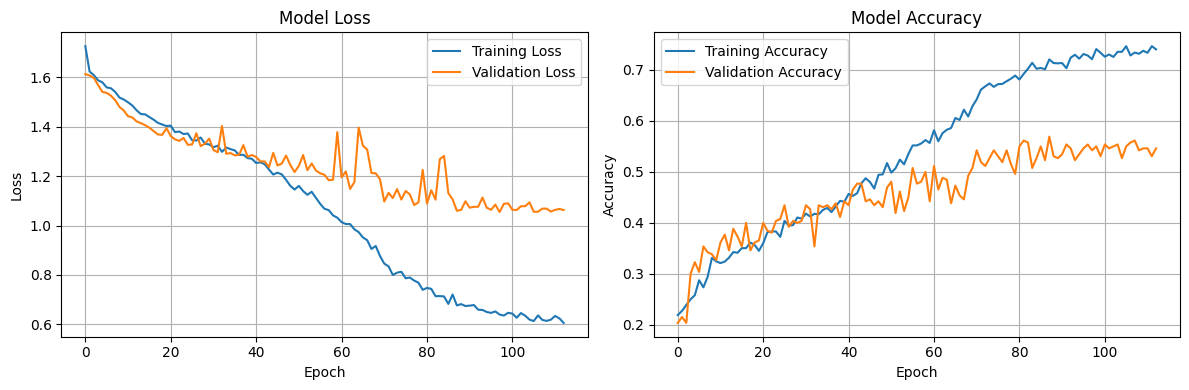

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step
Final Test Accuracy: 0.5077


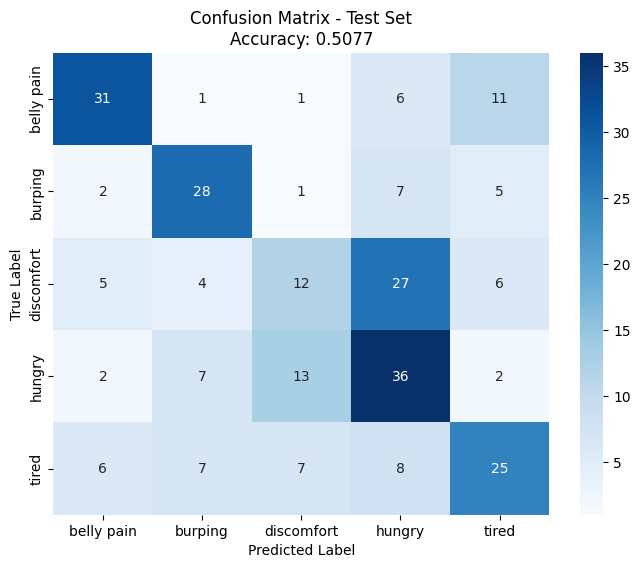

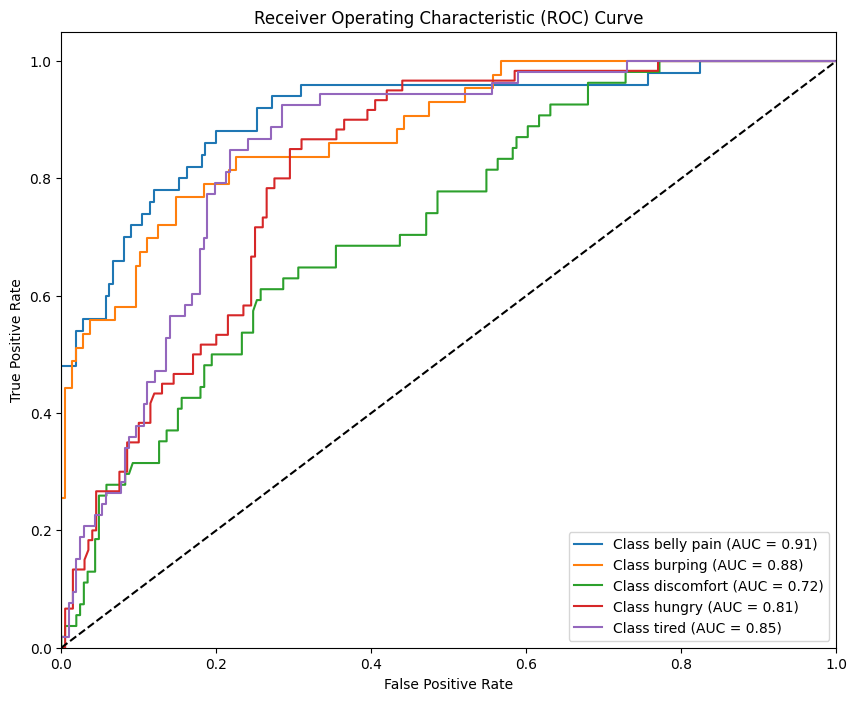


Classification Report (Test Set):
              precision    recall  f1-score   support

  belly pain       0.67      0.62      0.65        50
     burping       0.60      0.65      0.62        43
  discomfort       0.35      0.22      0.27        54
      hungry       0.43      0.60      0.50        60
       tired       0.51      0.47      0.49        53

    accuracy                           0.51       260
   macro avg       0.51      0.51      0.51       260
weighted avg       0.50      0.51      0.50       260


Saving final model and label encoder...

=== Training and Evaluation Complete ===
Model saved to: model_output/deepcnn_final.h5
Label encoder saved to: model_output/label_encoder.pkl


In [ ]:
if __name__ == "__main__":
    # ตรวจสอบและตั้งค่าการใช้งาน GPU (ถ้ามี)
    gpus = tf.config.experimental.list_physical_devices('GPU')
    if gpus:
        try:
            for gpu in gpus:
                # ตั้งค่าให้ TensorFlow จัดการหน่วยความจำ GPU แบบไดนามิก
                tf.config.experimental.set_memory_growth(gpu, True)
            print(f"GPU available: {len(gpus)} GPU(s)")
        except RuntimeError as e:
            print(e)
    else:
        print("GPU not available, using CPU")

    # เริ่มการทำงานของโปรแกรม
    main()

**เหตุผลที่เลือกโมเดลนี้:** เราใช้ Mel-spectrogram ร่วมกับ CNN เพราะเสียงร้องของเด็กมีลักษณะเป็นข้อมูลเวลา (time-
series) ที่ซับซ้อน ซึ่งเมื่อนำมาแปลงเป็น Mel-spectrogram จะทำให้เห็นรูปแบบความถี่ในแต่ละ
ช่วงเวลาเหมือนภาพ ทำให้ CNN ซึ่งถนัดการวิเคราะห์ลักษณะเชิงพื้นที่ (spatial patterns) สามารถ
เรียนรู้ลักษณะเฉพาะของเสียงในแต่ละย่านได้อย่างมีประสิทธิภาพ

# **Comparative model**

In [ ]:
# === Cell 1: ติดตั้งแพ็กเกจที่ต้องใช้ ===
!pip install -q transformers==4.21.0 datasets soundfile librosa torch torchaudio
!pip install -q matplotlib seaborn scikit-learn pandas numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.0/82.0 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 220.7/220.7 kB 12.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.9 MB/s e

In [ ]:
# ============================================
# [Cell 2] Import ไลบรารีและตั้งค่าเบื้องต้น
# - รวมทั้งกำหนด device (cuda/cpu)
# - ปิดคำเตือนรบกวน
# ============================================
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio

from transformers import Wav2Vec2Processor, Wav2Vec2Model

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
import seaborn as sns
from torch.optim.lr_scheduler import ReduceLROnPlateau
import warnings
import zipfile
import shutil
from IPython.display import clear_output
import time

warnings.filterwarnings('ignore')

# ตั้งค่า matplotlib สำหรับ Colab
plt.style.use('default')
%matplotlib inline

# เลือกอุปกรณ์ประมวลผล
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device


device(type='cuda')

In [ ]:
# ============================================
# [Cell 3] Focal Loss สำหรับจัดการ class imbalance
# - ใช้ cross entropy พื้นฐาน + โทษตัวอย่างที่โมเดลมั่นใจผิด (gamma)
# ============================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, num_classes=5):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.num_classes = num_classes

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')   # CE per-sample
        pt = torch.exp(-ce_loss)                                       # ความน่าจะเป็นของคลาสที่ถูกต้อง
        focal_loss = self.alpha * (1 - pt)**self.gamma * ce_loss       # โทษตัวอย่างที่ทำนายได้ไม่ดีมากกว่า
        return focal_loss.mean()


In [ ]:
# ============================================
# [Cell 4] Dataset สำหรับอ่านไฟล์เสียง
# - โหลด .wav ด้วย torchaudio
# - แปลงเป็นโมโน/รีแซมเปิลเป็น 16k
# - pad/truncate ให้ยาวเท่ากัน (7 วินาที)
# - แปลงผ่าน Wav2Vec2Processor -> input_values
# ============================================
class AudioDataset(Dataset):
    def __init__(self, file_paths, labels, processor, max_length=16000*7):
        self.file_paths = file_paths
        self.labels = labels
        self.processor = processor
        self.max_length = max_length

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        try:
            waveform, sample_rate = torchaudio.load(self.file_paths[idx])

            # ทำเป็นโมโนถ้าเป็นสเตอริโอ
            if waveform.shape[0] > 1:
                waveform = torch.mean(waveform, dim=0, keepdim=True)

            # รีแซมเปิลเป็น 16k
            if sample_rate != 16000:
                resampler = torchaudio.transforms.Resample(sample_rate, 16000)
                waveform = resampler(waveform)

            # flatten เป็น 1D (Tensor -> Numpy)
            waveform = waveform.squeeze().numpy()

            # pad/truncate ให้ยาวเท่ากัน
            if len(waveform) > self.max_length:
                waveform = waveform[:self.max_length]
            else:
                waveform = np.pad(waveform, (0, self.max_length - len(waveform)), 'constant')

            # ประมวลผลด้วย Wav2Vec2 processor
            inputs = self.processor(
                waveform,
                sampling_rate=16000,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=self.max_length
            )

            return {
                'input_values': inputs.input_values.squeeze(),
                'labels': torch.tensor(self.labels[idx], dtype=torch.long)
            }
        except Exception as e:
            print(f"Error loading {self.file_paths[idx]}: {e}")
            return {
                'input_values': torch.zeros(self.max_length),
                'labels': torch.tensor(0, dtype=torch.long)
            }


In [ ]:
# ============================================
# [Cell 5] โมเดล Wav2Vec2 + หัว Classification
# - โหลดพารามิเตอร์จากโมเดลพรีเทรน
# - freeze feature_extractor + บาง encoder layers เพื่อลดใช้เมมโมรี
# - ใช้ mean pooling แล้วส่งเข้า classifier
# ============================================
class Wav2Vec2Classifier(nn.Module):
    def __init__(self, model_name="Wiam/baby-cry-classification-finetuned-babycry-v4", num_classes=5, dropout=0.3):
        super(Wav2Vec2Classifier, self).__init__()

        self.wav2vec2 = Wav2Vec2Model.from_pretrained(model_name)

        # freeze feature extractor
        for param in self.wav2vec2.feature_extractor.parameters():
            param.requires_grad = False

        # freeze บาง encoder layers (เช่น 6 ชั้นแรก)
        for i, layer in enumerate(self.wav2vec2.encoder.layers):
            if i < 6:
                for param in layer.parameters():
                    param.requires_grad = False

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(self.wav2vec2.config.hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_values, attention_mask=None):
        outputs = self.wav2vec2(input_values, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state             # [batch, seq_len, hidden]
        pooled = hidden_states.mean(dim=1)                    # mean pooling -> [batch, hidden]
        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)
        return logits


In [ ]:
# ============================================
# [Cell 6] EarlyStopping ช่วยหยุดเทรนเมื่อ val loss ไม่ดีขึ้น
# ============================================
class EarlyStopping:
    def __init__(self, patience=7, min_delta=0.001, restore_best_weights=True):
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.best_loss = None
        self.counter = 0
        self.best_weights = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(model)
        elif val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.save_checkpoint(model)
        else:
            self.counter += 1

        if self.counter >= self.patience:
            if self.restore_best_weights:
                model.load_state_dict(self.best_weights)
            return True
        return False

    def save_checkpoint(self, model):
        self.best_weights = model.state_dict().copy()


In [ ]:
# ============================================
# [Cell 7] ฟังก์ชันช่วยจัดเตรียมข้อมูล
# - setup_data(): ตัวเลือกอัปโหลด/Drive/URL (คงโครงไว้)
# - load_data(): โหลดแบบโฟลเดอร์มี train/val/test
# - load_full_data(): โหลดแบบโฟลเดอร์รวม (class subfolders) -> ให้เรา split เอง
# - split_data(): (ตามที่ผู้ใช้ให้มา) แบ่ง 80/10/10 (stratify)
# ============================================
def setup_data():
    """
    Setup data ใน Colab: (1) อัปโหลด zip, (2) ใช้ Google Drive, (3) ดาวน์โหลดจาก URL
    """
    print("Choose data source:")
    print("1. Upload ZIP file")
    print("2. Use Google Drive")
    print("3. Download from URL")

    choice = input("Enter choice (1/2/3): ")

    if choice == "1":
        from google.colab import files
        print("Please upload your data.zip file...")
        uploaded = files.upload()
        zip_name = list(uploaded.keys())[0]
        with zipfile.ZipFile(zip_name, 'r') as zip_ref:
            zip_ref.extractall('/content/data')
        print("Data extracted to /content/data")
        return '/content/data'

    elif choice == "2":
        drive_path = input("Enter full path to your data folder in Drive (e.g., /content/drive/MyDrive/audio_data): ")
        if os.path.exists(drive_path):
            shutil.copytree(drive_path, '/content/data')
            print("Data copied from Drive to /content/data")
            return '/content/data'
        else:
            print("Path not found!")
            return None

    elif choice == "3":
        url = input("Enter download URL: ")
        !wget -O data.zip "{url}"
        with zipfile.ZipFile('data.zip', 'r') as zip_ref:
            zip_ref.extractall('/content/data')
        print("Data downloaded and extracted to /content/data")
        return '/content/data'

def load_data(data_dir):
    """
    โหลดข้อมูลแบบโครงสร้าง:
    data_dir/
        train/
            class1/
            class2/
        val/
            ...
        test/
            ...
    """
    def get_files_and_labels(split_dir):
        files, labels, classes = [], [], []
        if not os.path.exists(split_dir):
            return files, labels, classes
        classes = sorted([d for d in os.listdir(split_dir) if os.path.isdir(os.path.join(split_dir, d))])
        for i, class_name in enumerate(classes):
            class_dir = os.path.join(split_dir, class_name)
            for file in os.listdir(class_dir):
                if file.endswith('.wav'):
                    files.append(os.path.join(class_dir, file))
                    labels.append(i)
        return files, labels, classes

    train_files, train_labels, class_names = get_files_and_labels(os.path.join(data_dir, 'train'))
    val_files, val_labels, _ = get_files_and_labels(os.path.join(data_dir, 'val'))
    test_files, test_labels, _ = get_files_and_labels(os.path.join(data_dir, 'test'))

    return (train_files, train_labels), (val_files, val_labels), (test_files, test_labels), class_names

def load_full_data(data_dir):
    """
    โหลดข้อมูลแบบโฟลเดอร์รวม:
    data_dir/
        class1/
        class2/
        ...
    คืนค่า: X_all (list เส้นทางไฟล์), y_encoded_all (list label int), class_names
    """
    class_names = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
    X_all, y_all = [], []

    label_map = {cls: i for i, cls in enumerate(class_names)}
    for cls in class_names:
        class_dir = os.path.join(data_dir, cls)
        for f in os.listdir(class_dir):
            if f.endswith('.wav'):
                X_all.append(os.path.join(class_dir, f))
                y_all.append(label_map[cls])

    return X_all, y_all, class_names

# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
# ฟังก์ชัน split_data() ตามที่ผู้ใช้ให้มา (เพิ่มเข้าโค้ตแล้ว)
# มีการ import train_test_split แล้วใน Cell 2
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
def split_data(X, y, y_encoded):
    """
    แบ่งข้อมูลเป็นชุด Training, Validation, และ Test
    :param X: ข้อมูล feature (ที่นี่คือ list ของเส้นทางไฟล์เสียง)
    :param y: ข้อมูล label (one-hot) (จะไม่ได้ใช้งานตรง ๆ ใน Dataset แต่อยู่เพื่อให้ฟังก์ชันทำงานครบ)
    :param y_encoded: ข้อมูล label (ตัวเลข)
    :return: X_train, X_val, X_test, y_train, y_val, y_test, y_enc_train, y_enc_val, y_enc_test
    """
    # 80% train, 20% temp
    X_train, X_temp, y_train, y_temp, y_enc_train, y_enc_temp = train_test_split(
        X, y, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )
    # temp แบ่งครึ่งเป็น val/test -> 10%/10%
    X_val, X_test, y_val, y_test, y_enc_val, y_enc_test = train_test_split(
        X_temp, y_temp, y_enc_temp, test_size=0.5, random_state=42, stratify=y_enc_temp
    )
    print(f"Training set: {len(X_train)} samples")
    print(f"Validation set: {len(X_val)} samples")
    print(f"Test set: {len(X_test)} samples")
    return X_train, X_val, X_test, y_train, y_val, y_test, y_enc_train, y_enc_val, y_enc_test


In [ ]:
# ============================================
# [Cell 8] ฟังก์ชันช่วยวิเคราะห์/แสดงผล
# - plot_confusion_matrix(): heatmap
# - plot_training_curves(): loss/acc ตาม epoch
# - train_epoch(), validate_epoch(): วงจรเทรน/วัดผล
# - print_class_distribution(): แจกแจงคลาส
# ============================================
def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix"):
    plt.figure(figsize=(10, 8))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title, fontsize=16)
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('Actual', fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_training_curves(train_losses, val_losses, train_accs, val_accs):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    epochs = range(1, len(train_losses) + 1)
    ax1.plot(epochs, train_losses, label='Training Loss', linewidth=2)
    ax1.plot(epochs, val_losses, label='Validation Loss', linewidth=2)
    ax1.set_title('Training and Validation Loss', fontsize=14)
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(epochs, train_accs, label='Training Accuracy', linewidth=2)
    ax2.plot(epochs, val_accs, label='Validation Accuracy', linewidth=2)
    ax2.set_title('Training and Validation Accuracy', fontsize=14)
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for batch_idx, batch in enumerate(dataloader):
        input_values = batch['input_values'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_values)
        loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        if batch_idx % 10 == 0:
            print(f'Batch {batch_idx}/{len(dataloader)}, Loss: {loss.item():.4f}', end='\r')

    return total_loss / len(dataloader), 100. * correct / total

def validate_epoch(model, dataloader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in dataloader:
            input_values = batch['input_values'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_values)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return total_loss / len(dataloader), 100. * correct / total, all_preds, all_labels

def print_class_distribution(labels, class_names, split_name):
    labels = np.array(labels)
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n{split_name} Class Distribution:")
    for class_idx, count in zip(unique, counts):
        print(f"  {class_names[class_idx]}: {count} samples ({count/len(labels)*100:.1f}%)")


In [ ]:
# ============================================
# [Cell 9] main(): โฟลว์หลัก
# - โหลดข้อมูล: รองรับ 2 โหมด
#   (A) โฟลเดอร์ train/val/test -> ใช้ได้เลย
#   (B) โฟลเดอร์รวม -> ใช้ split_data(...) แบ่ง 80/10/10
# - เตรียม Dataset/DataLoader
# - เทรน/วัดผล/แสดงผล/บันทึกโมเดล
# ============================================
def main2():
    clear_output(wait=True)

    print("🎵 Wav2Vec2 Audio Classification with Focal Loss")
    print("=" * 60)

    # ===== คอนฟิก (เหมาะกับ Colab) =====
    BATCH_SIZE   = 8
    LEARNING_RATE= 5e-5
    NUM_EPOCHS   = 30
    PATIENCE     = 8

    print(f"Configuration:\n  Batch Size: {BATCH_SIZE}\n  Learning Rate: {LEARNING_RATE}\n"
          f"  Max Epochs: {NUM_EPOCHS}\n  Early Stopping Patience: {PATIENCE}\n  Device: {device}")

    # ===== ระบุตำแหน่งข้อมูล =====
    # ตัวอย่าง: โฟลเดอร์รวมแบบ class subfolders เช่น:
    # /content/new_cry_baby_dataset/
    #   ├── classA/*.wav
    #   └── classB/*.wav
    #
    # หรือแบบมี train/val/test:
    # /content/new_cry_baby_dataset_80_10_10/
    #   ├── train/classA/*.wav
    #   ├── val/classA/*.wav
    #   └── test/classA/*.wav
    DATA_DIR = "/content/drive/MyDrive/new_cry_baby_dataset_80_10_10/cry_baby_dataset"  # แก้เป็นของคุณได้

    if not os.path.exists(DATA_DIR):
        print("❌ Data directory not found! Please upload your data or modify DATA_DIR.")
        return

    # ===== ลองโหลดแบบ train/val/test ก่อน =====
    print("\n📊 Loading data...")
    (train_f, train_l), (val_f, val_l), (test_f, test_l), class_names = load_data(DATA_DIR)

    use_folder_split = len(train_f) > 0 and len(val_f) > 0 and len(test_f) > 0
    if use_folder_split:
        # โครงสร้างโฟลเดอร์พร้อมใช้
        print("✅ Found train/val/test folders.")
        print(f"  Training samples   : {len(train_f)}")
        print(f"  Validation samples : {len(val_f)}")
        print(f"  Test samples       : {len(test_f)}")
    else:
        # ไม่มี train/val/test -> โหลดแบบรวมแล้วใช้ split_data()
        print("ℹ️ train/val/test folders not found. Falling back to single-folder split (80/10/10).")
        X_all, y_encoded_all, class_names = load_full_data(DATA_DIR)

        if len(X_all) == 0:
            print("❌ No .wav files found.")
            return

        # one-hot y สำหรับให้ฟังก์ชัน split_data ตรงตามสเปค
        num_classes = len(class_names)
        y_onehot_all = np.eye(num_classes)[np.array(y_encoded_all)]  # shape: [N, C]

        # เรียกใช้ split_data(...) ที่คุณให้มา
        X_train, X_val, X_test, y_train_oh, y_val_oh, y_test_oh, y_enc_train, y_enc_val, y_enc_test = \
            split_data(X_all, y_onehot_all, y_encoded_all)

        # กำหนดตัวแปรให้เหมือนโหมดโฟลเดอร์
        train_f, val_f, test_f = X_train, X_val, X_test
        train_l, val_l, test_l = y_enc_train, y_enc_val, y_enc_test

        print(f"Classes: {class_names}")

    # ===== แจกแจงคลาสในแต่ละ split =====
    print_class_distribution(train_l, class_names, "Training")
    print_class_distribution(val_l, class_names, "Validation")
    print_class_distribution(test_l, class_names, "Test")

    # ===== เตรียม processor และโมเดล =====
    print("\n🤖 Initializing model...")
    try:
        processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")
        model = Wav2Vec2Classifier(num_classes=len(class_names)).to(device)
        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"✅ Model initialized with {trainable_params:,} trainable parameters")
    except Exception as e:
        print(f"❌ Error initializing model: {e}")
        return

    # ===== สร้าง Dataset & DataLoader =====
    print("\n📦 Creating datasets/dataloaders...")
    train_dataset = AudioDataset(train_f, train_l, processor)
    val_dataset   = AudioDataset(val_f,   val_l,   processor)
    test_dataset  = AudioDataset(test_f,  test_l,  processor)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

    # ===== Loss / Optimizer / Scheduler / EarlyStopping =====
    criterion = FocalLoss(alpha=1, gamma=2, num_classes=len(class_names))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5, verbose=True)
    early_stopping = EarlyStopping(patience=PATIENCE)

    # ===== วนเทรน =====
    print("\n🚀 Starting training...")
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    best_val_acc = 0.0
    start_time = time.time()

    for epoch in range(NUM_EPOCHS):
        print(f"\n📈 Epoch {epoch+1}/{NUM_EPOCHS}")
        print("-"*40)

        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, _, _ = validate_epoch(model, val_loader, criterion, device)

        scheduler.step(va_loss)

        train_losses.append(tr_loss)
        val_losses.append(va_loss)
        train_accs.append(tr_acc)
        val_accs.append(va_acc)

        print(f"🏋️  Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.2f}%")
        print(f"🎯 Val   Loss: {va_loss:.4f} | Val   Acc: {va_acc:.2f}%")

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            print(f"🎉 New best validation accuracy: {best_val_acc:.2f}%")

        if early_stopping(va_loss, model):
            print(f"\n⏹️  Early stopping triggered at epoch {epoch+1}")
            break

        torch.cuda.empty_cache()

    elapsed = (time.time() - start_time) / 60
    print(f"\n⏱️  Training completed in {elapsed:.1f} minutes")

    # ===== กราฟ loss/acc =====
    print("\n📊 Plotting training curves...")
    plot_training_curves(train_losses, val_losses, train_accs, val_accs)

    # ===== ประเมินบน test =====
    print("\n🧪 Evaluating on test set...")
    test_loss, test_acc, test_preds, test_labels_int = validate_epoch(model, test_loader, criterion, device)
    print(f"📊 Test Results:\n  Test Loss: {test_loss:.4f}\n  Test Accuracy: {test_acc:.2f}%")

    print("\n📈 Classification Report:")
    print(classification_report(test_labels_int, test_preds, target_names=class_names))

    print("\n🔍 Confusion Matrix:")
    plot_confusion_matrix(test_labels_int, test_preds, class_names, "Test Set Confusion Matrix")

    # ===== บันทึกโมเดล =====
    model_path = '/content/wav2vec2_classifier_best.pth'
    torch.save(model.state_dict(), model_path)
    print(f"\n💾 Model saved as '{model_path}'")

    # บันทึกไปยัง Google Drive (ถ้ามี)
    try:
        drive_path = '/content/drive/MyDrive/wav2vec2_classifier_best.pth'
        torch.save(model.state_dict(), drive_path)
        print(f"💾 Model also saved to Google Drive: '{drive_path}'")
    except Exception:
        pass

    print("\n✅ Training completed successfully!")
    print(f"🏆 Best validation accuracy: {best_val_acc:.2f}%")
    print(f"🎯 Final test accuracy: {test_acc:.2f}%")


🎵 Wav2Vec2 Audio Classification with Focal Loss
Configuration:
  Batch Size: 8
  Learning Rate: 5e-05
  Max Epochs: 30
  Early Stopping Patience: 8
  Device: cuda

📊 Loading data...
ℹ️ train/val/test folders not found. Falling back to single-folder split (80/10/10).
Training set: 520 samples
Validation set: 65 samples
Test set: 65 samples
Classes: ['belly pain', 'burping', 'discomfort', 'hungry', 'tired']

Training Class Distribution:
  belly pain: 99 samples (19.0%)
  burping: 86 samples (16.5%)
  discomfort: 108 samples (20.8%)
  hungry: 121 samples (23.3%)
  tired: 106 samples (20.4%)

Validation Class Distribution:
  belly pain: 12 samples (18.5%)
  burping: 11 samples (16.9%)
  discomfort: 14 samples (21.5%)
  hungry: 15 samples (23.1%)
  tired: 13 samples (20.0%)

Test Class Distribution:
  belly pain: 13 samples (20.0%)
  burping: 11 samples (16.9%)
  discomfort: 13 samples (20.0%)
  hungry: 15 samples (23.1%)
  tired: 13 samples (20.0%)

🤖 Initializing model...


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

✅ Model initialized with 235,947,141 trainable parameters

📦 Creating datasets/dataloaders...

🚀 Starting training...

📈 Epoch 1/30
----------------------------------------
🏋️  Train Loss: 1.0338 | Train Acc: 17.50%
🎯 Val   Loss: 1.0384 | Val   Acc: 20.00%
🎉 New best validation accuracy: 20.00%

📈 Epoch 2/30
----------------------------------------
🏋️  Train Loss: 1.0305 | Train Acc: 21.15%
🎯 Val   Loss: 1.0306 | Val   Acc: 23.08%
🎉 New best validation accuracy: 23.08%

📈 Epoch 3/30
----------------------------------------
🏋️  Train Loss: 1.0236 | Train Acc: 20.77%
🎯 Val   Loss: 1.0255 | Val   Acc: 23.08%

📈 Epoch 4/30
----------------------------------------
🏋️  Train Loss: 1.0300 | Train Acc: 20.58%
🎯 Val   Loss: 1.0248 | Val   Acc: 23.08%

📈 Epoch 5/30
----------------------------------------
🏋️  Train Loss: 1.0309 | Train Acc: 22.12%
🎯 Val   Loss: 1.0232 | Val   Acc: 23.08%

📈 Epoch 6/30
----------------------------------------
🏋️  Train Loss: 1.0325 | Train Acc: 20.77%
🎯 Val   Los

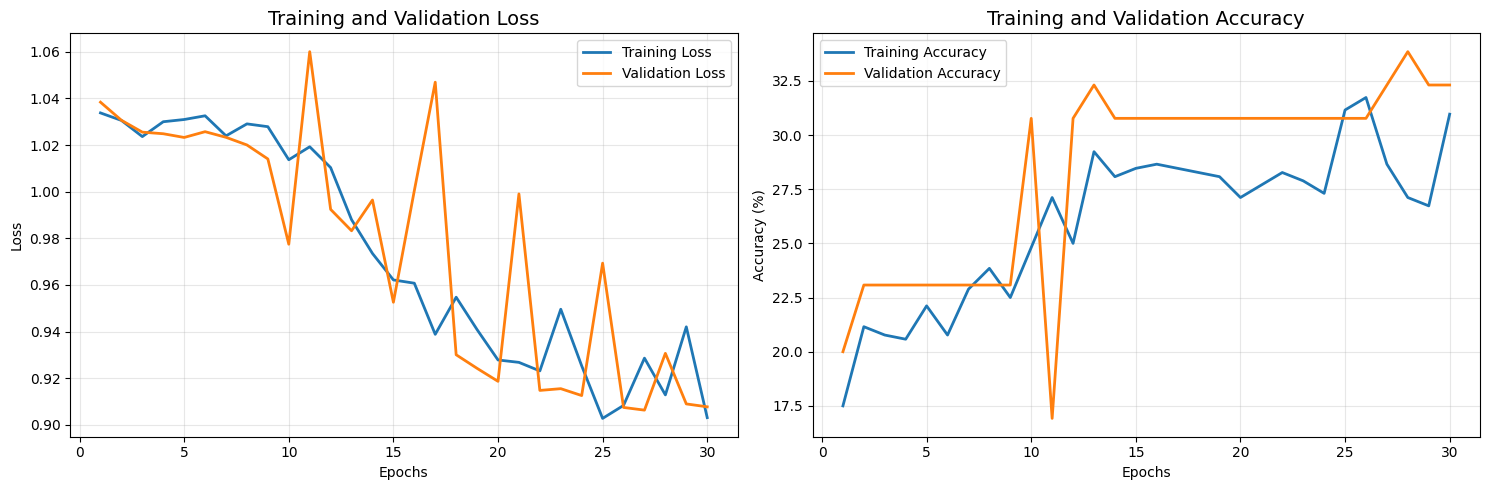


🧪 Evaluating on test set...
📊 Test Results:
  Test Loss: 0.8605
  Test Accuracy: 33.85%

📈 Classification Report:
              precision    recall  f1-score   support

  belly pain       0.42      0.38      0.40        13
     burping       1.00      0.27      0.43        11
  discomfort       0.00      0.00      0.00        13
      hungry       0.28      0.93      0.43        15
       tired       0.00      0.00      0.00        13

    accuracy                           0.34        65
   macro avg       0.34      0.32      0.25        65
weighted avg       0.32      0.34      0.25        65


🔍 Confusion Matrix:


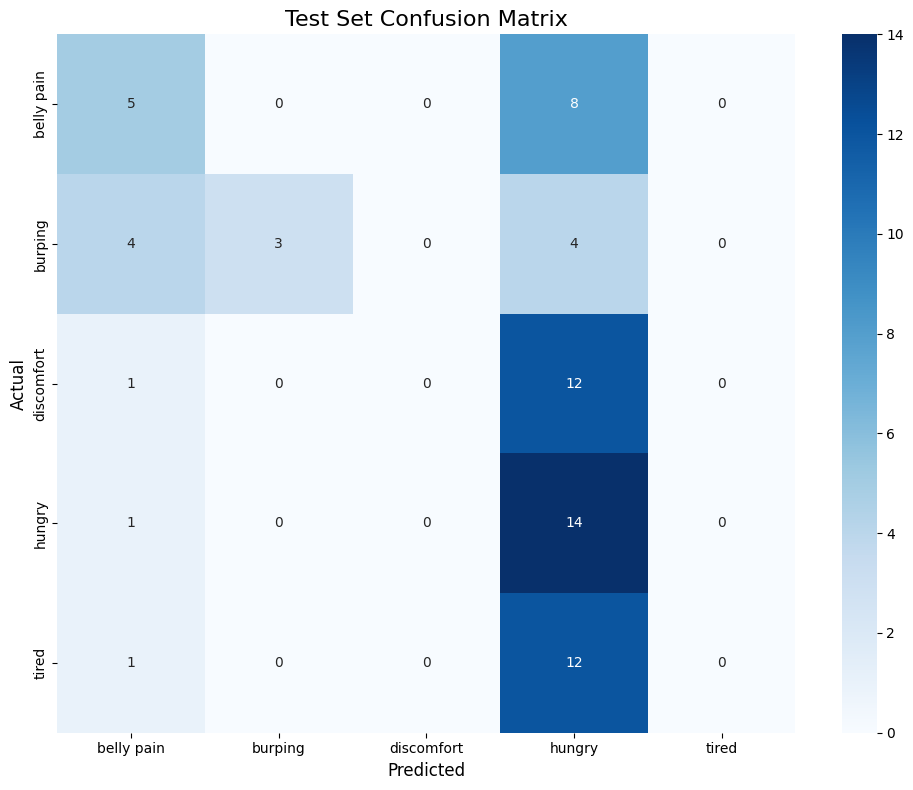


💾 Model saved as '/content/wav2vec2_classifier_best.pth'
💾 Model also saved to Google Drive: '/content/drive/MyDrive/wav2vec2_classifier_best.pth'

✅ Training completed successfully!
🏆 Best validation accuracy: 33.85%
🎯 Final test accuracy: 33.85%


In [ ]:
# ============================================
# [Cell 10] รัน main()
# ============================================
if __name__ == "__main__":
    main2()


**เหตุผลที่เลือกโมเดลนี้:** เป็น Model pretrain ที่ fine-turn เสียงเด็กมาโดยเฉพาะ

# **Comparison of 2 Models**

**Main Model**

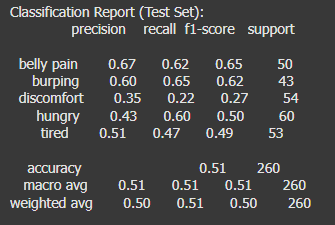

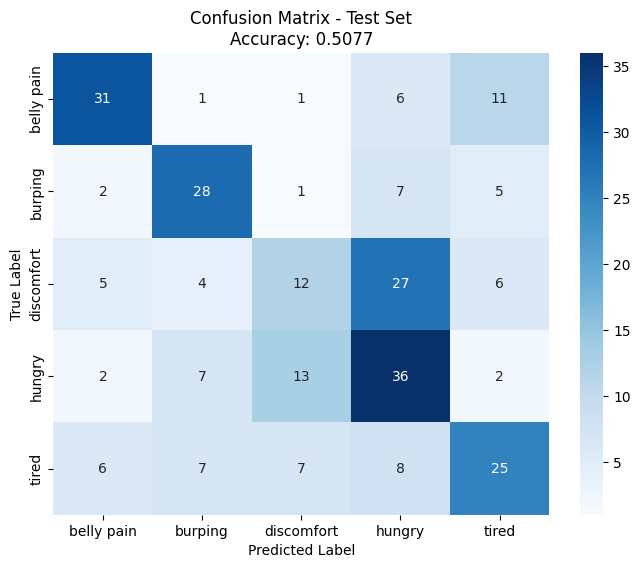

**Comparative model**

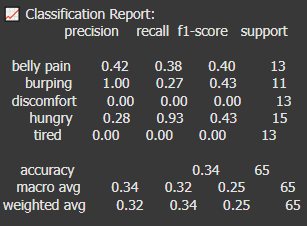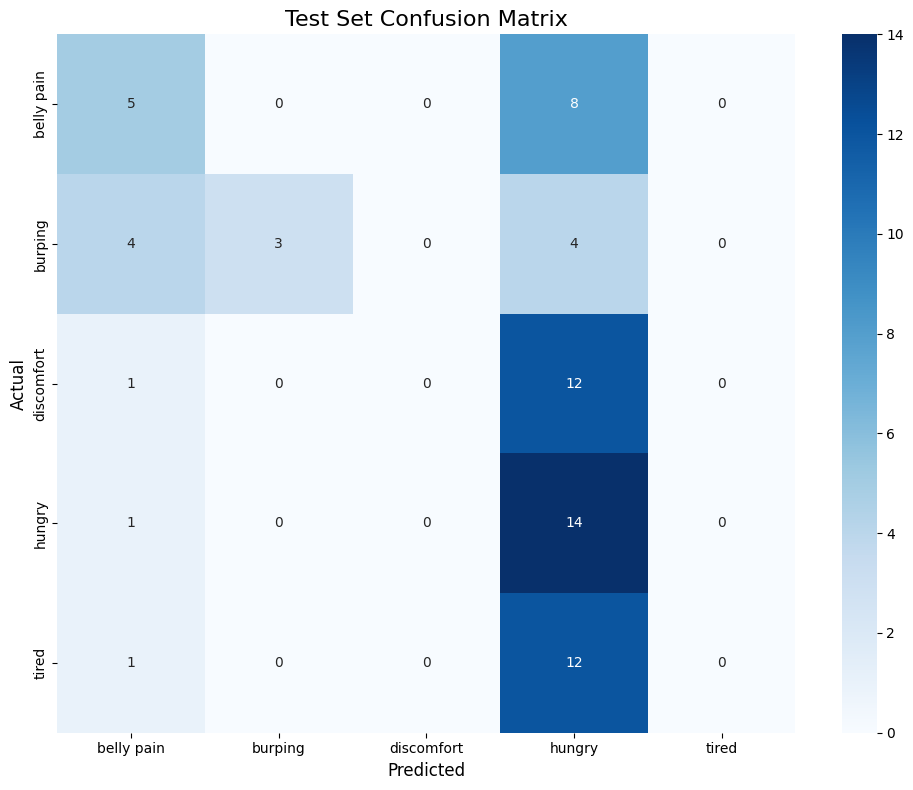

**ภาพรวมผลงาน**

• Main Model: Accuracy ≈ 0.51, macro-F1 ≈ 0.51

• Comparative model: Accuracy ≈ 0.34, macro-F1 ≈ 0.25

→ โดยรวม Main Model ชนะชัดเจน ทั้งความแม่นยำและความสมดุลระหว่างคลาส

**รายละเอียดเชิงคลาส**

-Main Model

• ดีสุด:

- belly pain F1=0.65 (recall 0.62), burping F1=0.62 (recall 0.65)

• อ่อนสุด:

- discomfort F1=0.27 (recall 0.22), tired F1=0.49

*รูปแบบความสับสน (จาก Confusion Matrix): discomfort → hungry สูงมาก (27 เคส), และ tired กระจายไปหลายคลาส*

-Comparative model

- hungry เด่นด้าน recall 0.93 แต่ precision 0.28 → ทาย “hungry” เยอะมากแต่ผิดบ่อย
- discomfort และ tired recall = 0.00 → แทบไม่ถูกทายเลย

*จาก Confusion Matrix จะเห็นว่าทุกคลาสถูกทายเป็น hungry จำนวนมาก: รวมประมาณ 50/65 ตัวอย่าง  ถูกทายเป็น hungry ชัดพอ ว่า B มี bias หนักไปทาง “hungry”*
